# TA-07: Q-Learning untuk Robot Kurir Pengantar Paket dengan Manajemen Baterai

**Mata Praktikum:** Pembelajaran Mesin | **Modul 07:** Reinforcement Learning (Q-Learning)
**Nama / NIM:** *[isi di sini]*

Notebook ini adalah lanjutan dari **TP-07** dan memuat seluruh alur Tugas Akhir:

1. Re-definisi State, Action, Reward dan implementasi lingkungan simulasi (Python murni, tanpa Gymnasium)
2. Implementasi Q-Learning dengan strategi ϵ-greedy
3. Analisis konvergensi lewat Kurva Pembelajaran
4. Ekstraksi dan interpretasi Kebijakan Optimal (Policy)
5. Eksperimen hiperparameter: pengaruh discount factor **γ**

Semua hasil memakai *random seed* tetap (42) sehingga dapat direproduksi. Angka bisa sedikit berbeda jika versi NumPy Anda berbeda.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs("figures", exist_ok=True)
SEED = 42

## 1. Re-definisi Skenario (S, A, R) dan Lingkungan

**Skenario:** Robot kurir mengantar satu paket di grid 5×5 sambil mengelola baterainya.

**Peta (baris 0-4 dari atas, kolom 0-4 dari kiri):**

```
 P . . . .        P = titik ambil paket (0,0)   -> robot MULAI di sini dengan baterai penuh
 . # . . .        D = titik tujuan      (4,4)
 . . . # .        C = stasiun pengisian (4,0)
 . # . . .        # = rintangan (1,1), (2,3), (3,1)
 C . . . D
```

| Elemen | Definisi |
|---|---|
| **State (S)** | (baris, kolom, status_paket, level_baterai). Posisi 25 × status paket 2 (0 = belum diambil, 1 = dibawa) × baterai 4 (0 = habis, 1 = rendah, 2 = sedang, 3 = penuh) = **200 state** |
| **Action (A)** | 7 aksi: 0 Atas, 1 Bawah, 2 Kiri, 3 Kanan, 4 Ambil Paket (hanya di P), 5 Serahkan Paket (hanya di D), 6 Isi Baterai (hanya di C) |
| **Reward (R)** | Setiap aksi **−1**. Ditambah: ambil paket **+20**, serahkan paket **+100**, aksi tidak valid / menabrak rintangan atau tepi **−10**, baterai habis **−50** |
| **Dinamika** | Perpindahan deterministik. Setiap perpindahan yang berhasil punya peluang **30%** menurunkan baterai satu level. Isi Baterai di C mengembalikan baterai ke penuh |
| **Episode berakhir** | Paket diserahkan di D (sukses), baterai mencapai 0 (gagal), atau 100 langkah (timeout) |

**Catatan perubahan dari TP-07:** TP-07 belum menetapkan posisi awal robot. Di sini ditetapkan di titik ambil P dengan baterai penuh. Aturan S, A, R tidak berubah. Karena biaya langkah −1 berlaku untuk **setiap** aksi, aksi tidak valid menghasilkan total −11 dan mengambil paket menghasilkan total +19.

In [2]:
GRID = 5
P_CELL = (0, 0)                      # titik ambil paket
D_CELL = (4, 4)                      # titik tujuan
C_CELL = (4, 0)                      # stasiun pengisian baterai
START = P_CELL                       # robot memulai di titik ambil dengan baterai penuh
OBSTACLES = {(1, 1), (2, 3), (3, 1)}

ACTIONS = ["Atas", "Bawah", "Kiri", "Kanan", "Ambil Paket", "Serahkan Paket", "Isi Baterai"]
MOVES = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
N_ACTIONS = len(ACTIONS)             # 7
N_BATTERY = 4                        # 0 = habis, 1 = rendah, 2 = sedang, 3 = penuh
N_STATES = GRID * GRID * 2 * N_BATTERY   # 25 x 2 x 4 = 200

# Reward (dijumlahkan: biaya langkah selalu berlaku, bonus/hukuman ditambahkan di atasnya)
R_STEP = -1
R_PICKUP = 20
R_DELIVER = 100
R_INVALID = -10
R_DEAD = -50
P_DRAIN = 0.3                        # peluang baterai turun 1 level saat robot berpindah

In [3]:
def encode(state):
    """(baris, kolom, status_paket, level_baterai) -> indeks 0..199."""
    r, c, pkg, bat = state
    return ((r * GRID + c) * 2 + pkg) * N_BATTERY + bat


def decode(idx):
    bat = idx % N_BATTERY
    idx //= N_BATTERY
    pkg = idx % 2
    idx //= 2
    return (idx // GRID, idx % GRID, pkg, bat)

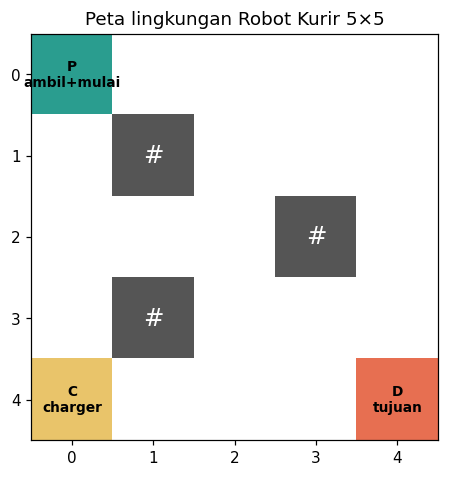

In [4]:
from matplotlib.colors import ListedColormap

def plot_map(ax=None):
    """Gambar peta lingkungan."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.8, 4.8))
    layout = np.zeros((GRID, GRID))
    for (r, c) in OBSTACLES:
        layout[r, c] = 1
    layout[P_CELL], layout[D_CELL], layout[C_CELL] = 2, 3, 4
    ax.imshow(layout, cmap=ListedColormap(["white", "#555555", "#2a9d8f", "#e76f51", "#e9c46a"]), vmin=0, vmax=4)
    names = {P_CELL: "P\nambil+mulai", D_CELL: "D\ntujuan", C_CELL: "C\ncharger"}
    for (r, c), t in names.items():
        ax.text(c, r, t, ha="center", va="center", fontsize=9, fontweight="bold")
    for (r, c) in OBSTACLES:
        ax.text(c, r, "#", ha="center", va="center", fontsize=16, color="white")
    ax.set_xticks(range(GRID)); ax.set_yticks(range(GRID)); ax.grid(False)
    ax.set_title("Peta lingkungan Robot Kurir 5×5")
    if show:
        plt.savefig("figures/environment_map.png", dpi=150, bbox_inches="tight")
        plt.show()

plot_map()

### Lingkungan simulasi
Fungsi `step(state, action)` menerima state dan action, lalu mengembalikan `new_state, reward, done` (ditambah `event` untuk mencatat sebab episode berakhir).

In [5]:
class KurirEnv:
    """Menerima (state, action) dan mengembalikan (new_state, reward, done, event)."""

    def __init__(self, seed=None, p_drain=P_DRAIN):
        self.rng = np.random.default_rng(seed)
        self.p_drain = p_drain

    def reset(self):
        return (START[0], START[1], 0, 3)

    def step(self, state, action):
        r, c, pkg, bat = state
        reward, done, event = R_STEP, False, None

        if action in MOVES:
            nr, nc = r + MOVES[action][0], c + MOVES[action][1]
            if not (0 <= nr < GRID and 0 <= nc < GRID) or (nr, nc) in OBSTACLES:
                reward += R_INVALID                      # menabrak rintangan / tepi grid
            else:
                r, c = nr, nc
                if self.rng.random() < self.p_drain:     # baterai turun secara acak
                    bat -= 1
                    if bat == 0:
                        reward += R_DEAD
                        done, event = True, "battery_dead"
        elif action == 4:                                # Ambil Paket
            if (r, c) == P_CELL and pkg == 0:
                pkg = 1
                reward += R_PICKUP
            else:
                reward += R_INVALID
        elif action == 5:                                # Serahkan Paket
            if (r, c) == D_CELL and pkg == 1:
                reward += R_DELIVER
                done, event = True, "delivered"
            else:
                reward += R_INVALID
        else:                                            # Isi Baterai
            if (r, c) == C_CELL:
                bat = 3
            else:
                reward += R_INVALID
        return (r, c, pkg, bat), reward, done, event

In [6]:
# Uji unit sederhana untuk memastikan aturan lingkungan sesuai definisi
env = KurirEnv(seed=0)
s = env.reset()
assert s == (0, 0, 0, 3)

s1, r, d, _ = env.step(s, 4)                      # ambil paket di P
assert (s1, r, d) == ((0, 0, 1, 3), R_STEP + R_PICKUP, False)
_, r, _, _ = env.step(s1, 4)                      # ambil lagi -> tidak valid
assert r == R_STEP + R_INVALID
_, r, _, _ = env.step((0, 0, 0, 3), 2)            # keluar tepi grid
assert r == R_STEP + R_INVALID
_, r, _, _ = env.step((1, 0, 0, 3), 3)            # menabrak rintangan (1,1)
assert r == R_STEP + R_INVALID
ns, r, d, ev = env.step((4, 4, 1, 3), 5)          # serahkan paket di D
assert (r, d, ev) == (R_STEP + R_DELIVER, True, "delivered")
ns, r, d, _ = env.step((4, 0, 1, 1), 6)           # isi baterai di C
assert ns == (4, 0, 1, 3) and r == R_STEP
dead_env = KurirEnv(seed=0, p_drain=1.0)          # baterai pasti turun
ns, r, d, ev = dead_env.step((1, 0, 1, 1), 1)
assert (ns[3], r, d, ev) == (0, R_STEP + R_DEAD, True, "battery_dead")
print("Semua uji lingkungan lolos.")

Semua uji lingkungan lolos.


## 2. Implementasi Q-Learning

Pembaruan Q-Table memakai Persamaan Bellman:

$$Q(s,a) \leftarrow (1-\alpha)\,Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a')\right]$$

Pada transisi terminal (paket sampai atau baterai habis) nilai masa depan tidak dihitung, jadi target = `r`. Strategi ϵ-greedy: dengan peluang ϵ pilih aksi acak (eksplorasi), selain itu pilih `argmax Q` (eksploitasi), dengan ϵ turun eksponensial: $\epsilon = \epsilon_{min} + (\epsilon_{max}-\epsilon_{min})\,e^{-\text{decay}\cdot episode}$.

In [7]:
def _greedy(q_row, rng):
    """Aksi terbaik; jika seri, pilih acak (menghindari bias ke aksi pertama)."""
    best = np.flatnonzero(q_row == q_row.max())
    return int(rng.choice(best))


def train_q_learning(alpha=0.8, gamma=0.9, episodes=6000, max_steps=100,
                     eps_start=1.0, eps_min=0.01, decay_rate=0.001,
                     seed=42, p_drain=P_DRAIN):
    """Melatih agen. Mengembalikan (q_table, history)."""
    env = KurirEnv(seed=seed, p_drain=p_drain)
    rng = np.random.default_rng(seed + 1)
    q = np.zeros((N_STATES, N_ACTIONS))
    rewards, successes, epsilons = [], [], []

    for ep in range(episodes):
        eps = eps_min + (eps_start - eps_min) * np.exp(-decay_rate * ep)
        state, total, outcome = env.reset(), 0.0, None
        for _ in range(max_steps):
            s = encode(state)
            a = int(rng.integers(N_ACTIONS)) if rng.random() < eps else _greedy(q[s], rng)   # epsilon-greedy
            new_state, r, done, event = env.step(state, a)
            ns = encode(new_state)
            target = r if done else r + gamma * q[ns].max()          # Persamaan Bellman
            q[s, a] = (1 - alpha) * q[s, a] + alpha * target
            total += r
            state = new_state
            if done:
                outcome = event
                break
        rewards.append(total)
        successes.append(1 if outcome == "delivered" else 0)
        epsilons.append(eps)

    return q, {"rewards": np.array(rewards), "successes": np.array(successes), "epsilons": np.array(epsilons)}


def evaluate_policy(q, n_episodes=1000, max_steps=100, seed=123, p_drain=P_DRAIN):
    """Mengikuti kebijakan greedy (tanpa eksplorasi) pada lingkungan baru."""
    env = KurirEnv(seed=seed, p_drain=p_drain)
    rewards, steps_ok, outcomes = [], [], {"delivered": 0, "battery_dead": 0, "timeout": 0}
    for _ in range(n_episodes):
        state, total, outcome = env.reset(), 0.0, "timeout"
        for t in range(1, max_steps + 1):
            a = int(np.argmax(q[encode(state)]))
            state, r, done, event = env.step(state, a)
            total += r
            if done:
                outcome = event
                if event == "delivered":
                    steps_ok.append(t)
                break
        rewards.append(total)
        outcomes[outcome] += 1
    return {
        "Tingkat sukses": outcomes["delivered"] / n_episodes,
        "Baterai habis": outcomes["battery_dead"] / n_episodes,
        "Timeout": outcomes["timeout"] / n_episodes,
        "Rata-rata reward": float(np.mean(rewards)),
        "Rata-rata langkah (sukses)": float(np.mean(steps_ok)) if steps_ok else float("nan"),
    }


def rollout(q, seed=7, max_steps=40, p_drain=P_DRAIN):
    """Satu episode greedy, dicatat langkah demi langkah (untuk demo / video)."""
    env = KurirEnv(seed=seed, p_drain=p_drain)
    state, log = env.reset(), []
    for t in range(1, max_steps + 1):
        a = int(np.argmax(q[encode(state)]))
        new_state, r, done, event = env.step(state, a)
        log.append({"Langkah": t, "State (baris,kolom,paket,baterai)": state, "Aksi": ACTIONS[a],
                    "Reward": r, "State berikutnya": new_state})
        state = new_state
        if done:
            break
    return log


def greedy_visit_counts(q, n_episodes=2000, max_steps=100, seed=321, p_drain=P_DRAIN):
    """Berapa kali tiap state dikunjungi saat mengikuti kebijakan greedy (untuk menandai state yang relevan)."""
    env = KurirEnv(seed=seed, p_drain=p_drain)
    counts = np.zeros(N_STATES, dtype=int)
    for _ in range(n_episodes):
        state = env.reset()
        for _ in range(max_steps):
            counts[encode(state)] += 1
            state, _, done, _ = env.step(state, int(np.argmax(q[encode(state)])))
            if done:
                break
    return counts


def moving_average(x, window=100):
    x = np.asarray(x, dtype=float)
    csum = np.cumsum(np.insert(x, 0, 0.0))
    out = np.empty_like(x)
    for i in range(len(x)):
        lo = max(0, i - window + 1)
        out[i] = (csum[i + 1] - csum[lo]) / (i + 1 - lo)
    return out


def convergence_episode(rewards, window=100, frac=0.9, tail=500):
    """Episode pertama saat rata-rata bergerak mencapai `frac` dari plateau (rata-rata `tail` episode terakhir).

    Mengembalikan (None, plateau) jika plateau tidak positif, artinya agen tidak konvergen ke kebijakan yang baik.
    """
    ma = moving_average(rewards, window)
    plateau = float(np.mean(rewards[-tail:]))
    if plateau <= 0:
        return None, plateau
    hit = np.flatnonzero(ma >= frac * plateau)
    return (int(hit[0]) if len(hit) else None), plateau

### Pemilihan hiperparameter awal
Modul menyarankan α=0.8 dan γ=0.9 sebagai contoh. Karena lingkungan ini **stokastik** (penurunan baterai acak), α yang besar membuat Q-Table terus "tersentak" oleh satu kejadian acak. Cell berikut membandingkan keduanya dengan jumlah episode yang sama.

In [8]:
rows = []
for a in [0.8, 0.1]:
    q_tmp, h_tmp = train_q_learning(alpha=a, gamma=0.9, seed=SEED)
    ev = evaluate_policy(q_tmp)
    rows.append({"alpha": a, **ev})
pd.DataFrame(rows).round(3)

,alpha,Tingkat sukses,Baterai habis,Timeout,Rata-rata reward,Rata-rata langkah (sukses)
0,0.8,0.734,0.266,0.0,69.166,12.104
1,0.1,0.888,0.112,0.0,91.743,12.151


**Hasil:** dengan α = 0.8, tingkat sukses hanya 73.4% (baterai habis 26.6%, rata-rata reward 69.2). Dengan α = 0.1, tingkat sukses naik menjadi 88.8% (baterai habis 11.2%, rata-rata reward 91.7).

**Penjelasan:** pada α = 0.8, setiap pembaruan mengganti 80% nilai lama dengan satu sampel baru. Karena baterai turun secara acak, satu kejadian sial (atau beruntung) langsung "menyeret" nilai Q, sehingga Q-Table berosilasi dan kebijakan akhirnya kurang andal. Pada α = 0.1, nilai Q lebih mirip rata-rata dari banyak pengalaman, sehingga lebih stabil di lingkungan stokastik. Karena itu seluruh notebook memakai **α = 0.1**, γ = 0.9.

In [9]:
# Hiperparameter utama yang dipakai di seluruh notebook
HYPER = dict(alpha=0.1, gamma=0.9, episodes=6000, max_steps=100,
             eps_start=1.0, eps_min=0.01, decay_rate=0.001)

q_table, hist = train_q_learning(**HYPER, seed=SEED)
print("Bentuk Q-Table:", q_table.shape, "= (jumlah state, jumlah aksi)")
print("State yang pernah dikunjungi:", int((q_table != 0).any(axis=1).sum()), "dari", N_STATES)
print("Epsilon awal -> akhir:", round(hist["epsilons"][0], 3), "->", round(hist["epsilons"][-1], 3))

Bentuk Q-Table: (200, 7) = (jumlah state, jumlah aksi)
State yang pernah dikunjungi: 128 dari 200
Epsilon awal -> akhir: 1.0 -> 0.012


## 3. Analisis Konvergensi (Kurva Pembelajaran)

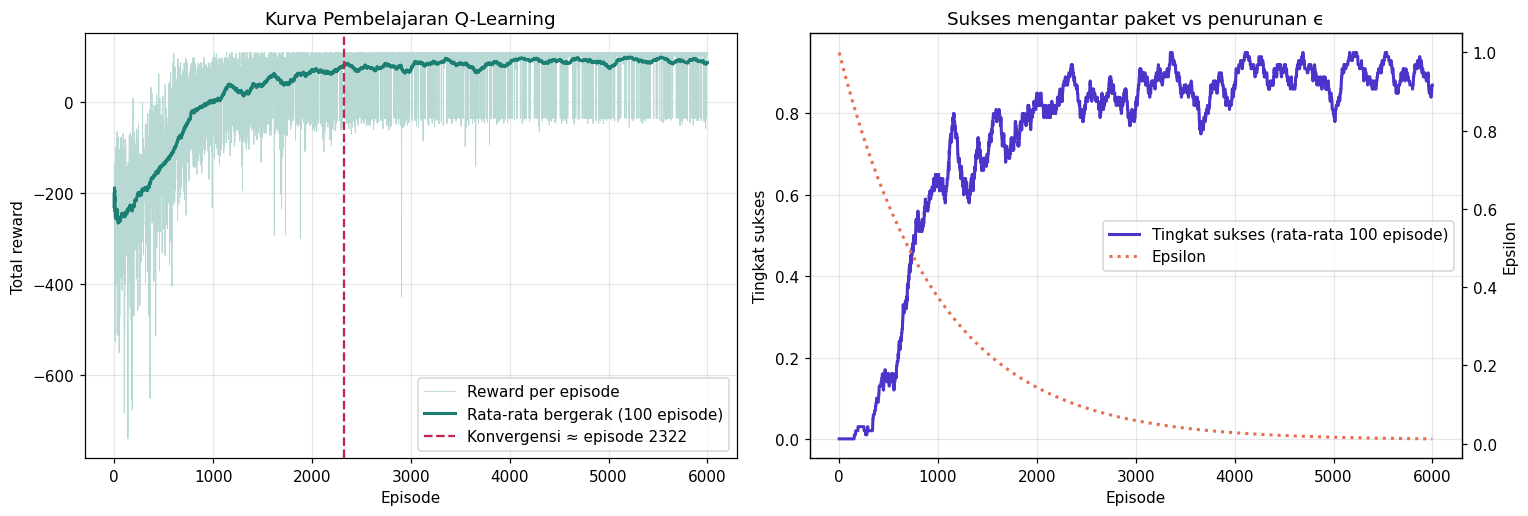

Plateau (rata-rata reward 500 episode terakhir): 90.9
Konvergensi (rata-rata bergerak pertama kali >= 90% plateau): episode 2322
Episode    0-500 : rata-rata reward   -192.0 | sukses 6.20% | ϵ rata-rata 0.79
Episode  500-1500: rata-rata reward     -5.0 | sukses 57.00% | ϵ rata-rata 0.39
Episode 1500-3000: rata-rata reward     68.9 | sukses 81.60% | ϵ rata-rata 0.12
Episode 3000-6000: rata-rata reward     89.1 | sukses 88.57% | ϵ rata-rata 0.03


In [10]:
WINDOW = 100
ma_reward = moving_average(hist["rewards"], WINDOW)
ma_success = moving_average(hist["successes"], WINDOW)
conv_ep, plateau = convergence_episode(hist["rewards"], window=WINDOW, frac=0.9, tail=500)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(hist["rewards"], color="#b8d8d4", linewidth=0.6, label="Reward per episode")
axes[0].plot(ma_reward, color="#1b7f73", linewidth=2, label=f"Rata-rata bergerak ({WINDOW} episode)")
if conv_ep is not None:
    axes[0].axvline(conv_ep, color="#c0264b", linestyle="--", label=f"Konvergensi ≈ episode {conv_ep}")
axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Total reward"); axes[0].set_title("Kurva Pembelajaran Q-Learning")
axes[0].legend(loc="lower right")

axes[1].plot(ma_success, color="#4b34c9", linewidth=2, label="Tingkat sukses (rata-rata 100 episode)")
ax2 = axes[1].twinx()
ax2.plot(hist["epsilons"], color="#e76f51", linestyle=":", linewidth=2, label="Epsilon")
ax2.set_ylabel("Epsilon"); ax2.grid(False)
axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Tingkat sukses"); axes[1].set_title("Sukses mengantar paket vs penurunan ϵ")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout()
fig.savefig("figures/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Plateau (rata-rata reward 500 episode terakhir): {plateau:.1f}")
print(f"Konvergensi (rata-rata bergerak pertama kali >= 90% plateau): episode {conv_ep}")
for lo, hi in [(0, 500), (500, 1500), (1500, 3000), (3000, 6000)]:
    print(f"Episode {lo:>4}-{hi:<4}: rata-rata reward {hist['rewards'][lo:hi].mean():8.1f} | sukses {hist['successes'][lo:hi].mean():.2%} | ϵ rata-rata {hist['epsilons'][lo:hi].mean():.2f}")

### Analisis Kurva Pembelajaran
*(Angka dari run dengan seed 42.)*

- **Konvergensi:** rata-rata bergerak 100 episode pertama kali mencapai 90% dari plateau di sekitar **episode 2322**, dan setelah sekitar episode 3000 kurva mendatar di kisaran reward **±90** (rata-rata 500 episode terakhir = 90.9).
- **Fase awal (episode 0-500):** rata-rata reward **−192.0**, tingkat sukses hanya **6.2%**, dengan ϵ rata-rata 0.79. Kurva sangat berfluktuasi dan banyak episode bernilai sangat negatif (sampai sekitar −700). Ini wajar karena agen hampir selalu bergerak acak: sering menabrak rintangan atau tepi (−11 per kejadian), kehabisan baterai (−50), atau memakai seluruh 100 langkah tanpa sampai tujuan.
- **Fase belajar (episode 500-1500):** reward naik tajam ke **−5.0** dan tingkat sukses ke **57.0%** saat ϵ turun ke sekitar 0.39. Agen mulai menemukan urutan ambil paket, turun, isi baterai, lalu ke tujuan, dan mulai memanfaatkannya.
- **Fase konvergensi (episode 1500 dan seterusnya):** reward rata-rata **68.9** (episode 1500-3000), lalu **89.1** (episode 3000-6000) dengan tingkat sukses sekitar **88.6%** dan ϵ tinggal sekitar 0.03.
- **Mengapa masih ada fluktuasi setelah konvergensi:** lingkungan ini stokastik. Walau kebijakannya sudah baik, baterai masih bisa turun beruntun secara acak. Episode yang berhasil bernilai sekitar +100, sedangkan yang gagal (baterai habis) bernilai jauh lebih rendah, sehingga rata-rata bergerak 100 episode tetap bergoyang. Sisa ϵ yang kecil (≈0.01-0.03) juga masih menyebabkan sedikit aksi acak.

## 4. Analisis dan Interpretasi Kebijakan (Policy)
Kebijakan optimal diambil dari `argmax Q(s,a)` untuk tiap state. Karena state memuat status paket dan level baterai, peta kebijakan dibuat per kombinasi (status paket × level baterai). Warna menunjukkan nilai state $V(s)=\max_a Q(s,a)$. Hanya state yang **benar-benar dilalui** kebijakan greedy yang digambar; tanda “·” berarti state itu tidak pernah dijumpai kebijakan (nilai Q-nya tidak terlatih, jadi tidak perlu dibaca).

In [11]:
def plot_policy(q, pkg, bat, ax, vmin=None, vmax=None, title=None, visits=None):
    """Peta kebijakan 5x5 untuk status paket `pkg` dan level baterai `bat`.

    Jika `visits` diberikan, hanya state yang pernah dikunjungi kebijakan greedy yang digambar;
    state lain diredupkan (nilai Q-nya tidak relevan karena tidak pernah dilalui).
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    symbols = {0: "↑", 1: "↓", 2: "←", 3: "→", 4: "ambil", 5: "antar", 6: "isi"}
    values = np.full((GRID, GRID), np.nan)
    relevant = np.zeros((GRID, GRID), dtype=bool)
    for r in range(GRID):
        for c in range(GRID):
            if (r, c) in OBSTACLES:
                continue
            s_idx = encode((r, c, pkg, bat))
            relevant[r, c] = (visits is None and np.any(q[s_idx])) or (visits is not None and visits[s_idx] > 0)
            if relevant[r, c]:
                values[r, c] = q[s_idx].max()
    lo = np.nanmin(values) if vmin is None else vmin
    hi = np.nanmax(values) if vmax is None else vmax
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#f1f1f1")
    im = ax.imshow(values, cmap=cmap, vmin=lo, vmax=hi)
    for r in range(GRID):
        for c in range(GRID):
            if (r, c) in OBSTACLES:
                ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color="#8a8a8a"))
                ax.text(c, r, "#", ha="center", va="center", fontsize=16, color="white")
            elif not relevant[r, c]:
                ax.text(c, r, "·", ha="center", va="center", fontsize=14, color="#bbbbbb")
            else:
                a = int(np.argmax(q[encode((r, c, pkg, bat))]))
                norm = (values[r, c] - lo) / max(1e-9, hi - lo)
                ax.text(c, r, symbols[a], ha="center", va="center", fontsize=18 if a < 4 else 9,
                        color="white" if norm < 0.6 else "black", fontweight="bold" if a >= 4 else "normal")
    for (r, c), tag in {P_CELL: "P", D_CELL: "D", C_CELL: "C"}.items():
        ax.text(c - 0.42, r - 0.32, tag, ha="left", va="center", fontsize=9, fontweight="bold", color="#e0a800")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if title:
        ax.set_title(title, fontsize=10)
    return im

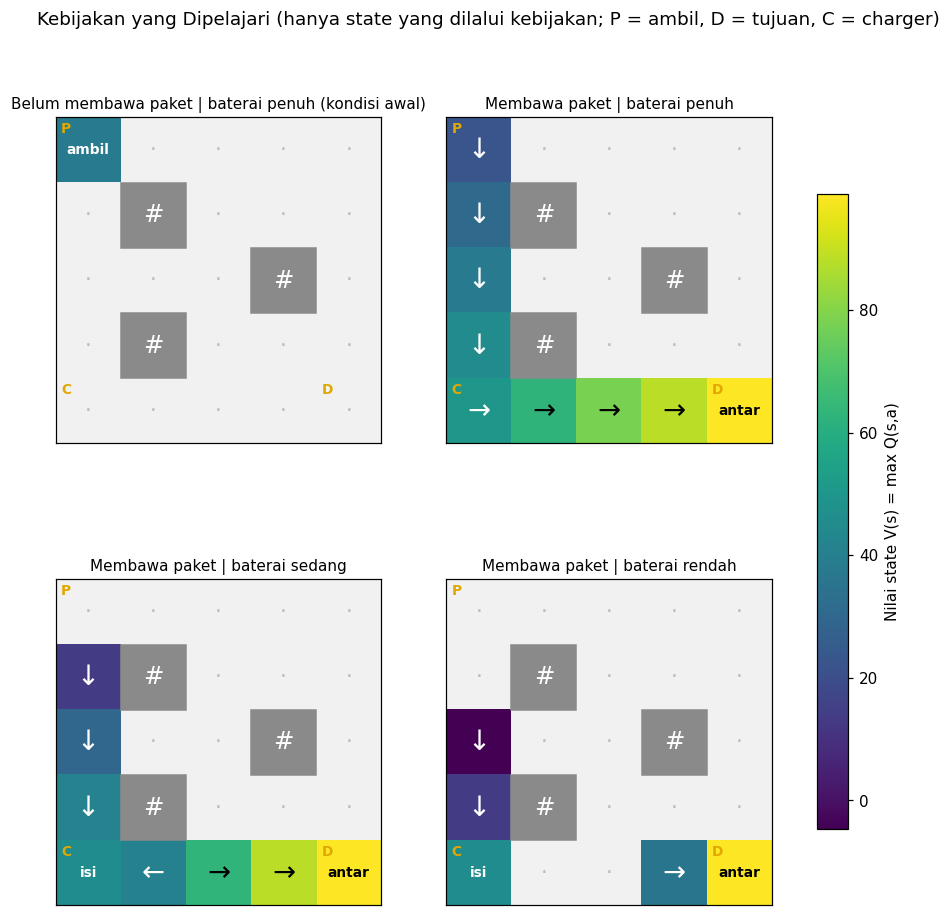

In [12]:
policy = np.argmax(q_table, axis=1)      # aksi terbaik untuk setiap state (indeks 0..199)
visits = greedy_visit_counts(q_table)    # state mana saja yang benar-benar dilalui kebijakan ini

relevant = visits > 0
vmin, vmax = q_table.max(axis=1)[relevant].min(), q_table.max(axis=1)[relevant].max()

panels = [(0, 3, "Belum membawa paket | baterai penuh (kondisi awal)"),
          (1, 3, "Membawa paket | baterai penuh"),
          (1, 2, "Membawa paket | baterai sedang"),
          (1, 1, "Membawa paket | baterai rendah")]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 10))
for ax, (pkg, bat, title) in zip(axes.ravel(), panels):
    im = plot_policy(q_table, pkg, bat, ax, vmin=vmin, vmax=vmax, title=title, visits=visits)
fig.colorbar(im, ax=axes, shrink=0.75, label="Nilai state V(s) = max Q(s,a)")
fig.suptitle("Kebijakan yang Dipelajari (hanya state yang dilalui kebijakan; P = ambil, D = tujuan, C = charger)", y=0.95)
fig.savefig("figures/policy_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Keputusan kunci: apa yang dilakukan robot di titik-titik penting?
key_states = [
    ("Awal: di P, belum bawa paket, baterai penuh", (0, 0, 0, 3)),
    ("Di C membawa paket, baterai penuh", (4, 0, 1, 3)),
    ("Di C membawa paket, baterai sedang", (4, 0, 1, 2)),
    ("Di C membawa paket, baterai rendah", (4, 0, 1, 1)),
    ("Di (4,1) membawa paket, baterai sedang", (4, 1, 1, 2)),
    ("Di (4,3) membawa paket, baterai rendah", (4, 3, 1, 1)),
    ("Di D membawa paket, baterai penuh", (4, 4, 1, 3)),
]
rows = []
for name, st in key_states:
    qs = q_table[encode(st)]
    rows.append({"Situasi": name, "Aksi terbaik": ACTIONS[int(np.argmax(qs))],
                 **{ACTIONS[a]: round(float(qs[a]), 1) for a in range(N_ACTIONS)}})
pd.DataFrame(rows).set_index("Situasi")

,Aksi terbaik,Atas,Bawah,Kiri,Kanan,Ambil Paket,Serahkan Paket,Isi Baterai
Situasi,,,,,,,,
"Awal: di P, belum bawa paket, baterai penuh",Ambil Paket,23.7,17.2,24.0,18.7,38.2,24.1,23.8
"Di C membawa paket, baterai penuh",Kanan,37.3,35.2,34.3,50.0,35.6,35.9,43.6
"Di C membawa paket, baterai sedang",Isi Baterai,25.5,30.0,29.7,20.2,28.6,29.4,45.7
"Di C membawa paket, baterai rendah",Isi Baterai,-9.3,29.2,29.1,-12.1,26.1,28.1,45.9
"Di (4,1) membawa paket, baterai sedang",Kiri,24.0,24.6,40.9,36.8,26.2,23.5,22.3
"Di (4,3) membawa paket, baterai rendah",Kanan,-11.0,9.0,-18.7,35.6,10.0,9.3,9.1
"Di D membawa paket, baterai penuh",Serahkan Paket,52.2,67.0,71.3,65.8,64.2,99.0,63.0


In [14]:
# Satu episode memakai kebijakan greedy (tanpa eksplorasi), dicatat langkah demi langkah
demo = pd.DataFrame(rollout(q_table, seed=7))
demo

,Langkah,"State (baris,kolom,paket,baterai)",Aksi,Reward,State berikutnya
0,1,"(0, 0, 0, 3)",Ambil Paket,19,"(0, 0, 1, 3)"
1,2,"(0, 0, 1, 3)",Bawah,-1,"(1, 0, 1, 3)"
2,3,"(1, 0, 1, 3)",Bawah,-1,"(2, 0, 1, 3)"
3,4,"(2, 0, 1, 3)",Bawah,-1,"(3, 0, 1, 3)"
4,5,"(3, 0, 1, 3)",Bawah,-1,"(4, 0, 1, 2)"
5,6,"(4, 0, 1, 2)",Isi Baterai,-1,"(4, 0, 1, 3)"
6,7,"(4, 0, 1, 3)",Kanan,-1,"(4, 1, 1, 3)"
7,8,"(4, 1, 1, 3)",Kanan,-1,"(4, 2, 1, 3)"
8,9,"(4, 2, 1, 3)",Kanan,-1,"(4, 3, 1, 2)"
9,10,"(4, 3, 1, 2)",Kanan,-1,"(4, 4, 1, 2)"


In [15]:
# Evaluasi kebijakan pada 1000 episode baru (tanpa eksplorasi)
ev_main = evaluate_policy(q_table, n_episodes=1000)
pd.Series(ev_main).round(3).to_frame("Nilai")

,Nilai
Tingkat sukses,0.888
Baterai habis,0.112
Timeout,0.000
Rata-rata reward,91.743
Rata-rata langkah (sukses),12.151


### Interpretasi Kebijakan
*(Angka dari run dengan seed 42.)*

**Alur berpikir agen berdasarkan peta kebijakan:**

1. **Di titik awal (P)** agen memilih **Ambil Paket** (Q = 38.2, jauh di atas aksi lain yang sekitar 17-24). Ini masuk akal karena bonus +20 hanya bisa didapat di sini.
2. **Setelah membawa paket**, agen menyusuri **kolom kiri ke bawah** menuju C, lalu **baris bawah ke kanan** menuju D. Rute ini bebas rintangan dan sekaligus **melewati stasiun pengisian C**, sehingga mengisi baterai hanya menambah 1 langkah.
3. **Keputusan di C bergantung pada level baterai.** Baterai **penuh**: agen langsung **Kanan** (Q = 50.0 lebih besar dari Isi Baterai = 43.6, karena mengisi saat penuh hanya membuang −1). Baterai **sedang**: **Isi Baterai** (Q = 45.7 vs Kanan 20.2). Baterai **rendah**: **Isi Baterai** (Q = 45.9 vs Kanan −12.1, bergerak dengan baterai rendah berisiko −50).
4. **Perilaku hati-hati:** pada baterai sedang, robot yang sudah sampai di (4,1) memilih **kembali ke C** untuk mengisi baterai (tanda ← di peta). Ini kebijakan yang cerdas karena sisa jarak ke D masih 3 langkah dan risiko kehabisan baterai lebih mahal daripada 2 langkah tambahan.
5. **Di D** agen memilih **Serahkan Paket** (Q = 99.0, tepat sama dengan −1 + 100).

**Contoh episode greedy (seed 7):** Ambil Paket → Bawah ×4 → (di C baterai sedang) Isi Baterai → Kanan ×4 → Serahkan Paket. Total **11 langkah** dengan total reward **109**.

**Apakah logis dan efisien?** Ya. Jumlah aksi minimum adalah 10 (ambil + 4 bawah + 4 kanan + serahkan) atau 11 dengan satu kali pengisian. Pada 1000 episode evaluasi, rata-rata langkah pada episode sukses adalah **12.15**, hanya sedikit di atas minimum karena sesekali agen berputar balik ke C untuk mengisi baterai. Tingkat sukses **88.8%**, baterai habis **11.2%**, dan **tidak ada timeout**. Seluruh kegagalan berasal dari penurunan baterai acak, bukan dari agen yang tersesat. Sebagai gambaran, peluang baterai turun tiga kali dalam empat langkah dari kondisi penuh sudah sekitar 8.4% untuk setiap ruas perjalanan (P ke C dan C ke D), jadi kegagalan di kisaran 10% wajar dan sulit dihindari.

**Catatan:** hanya 128 dari 200 state yang pernah dikunjungi saat pelatihan, dan peta kebijakan sengaja hanya menampilkan state yang benar-benar dilalui kebijakan. Nilai Q pada state lain tidak terlatih sehingga tidak perlu ditafsirkan.

## 5. Eksperimen Hiperparameter: Discount Factor γ
Satu hiperparameter saja (γ). Model dilatih dua kali dengan seed dan hiperparameter lain yang sama:

- **γ = 0.9** (nilai default, tinggi): agen memperhitungkan reward jangka panjang
- **γ = 0.1** (nilai ekstrem, sangat rendah): agen "miopik", hampir hanya peduli reward langsung

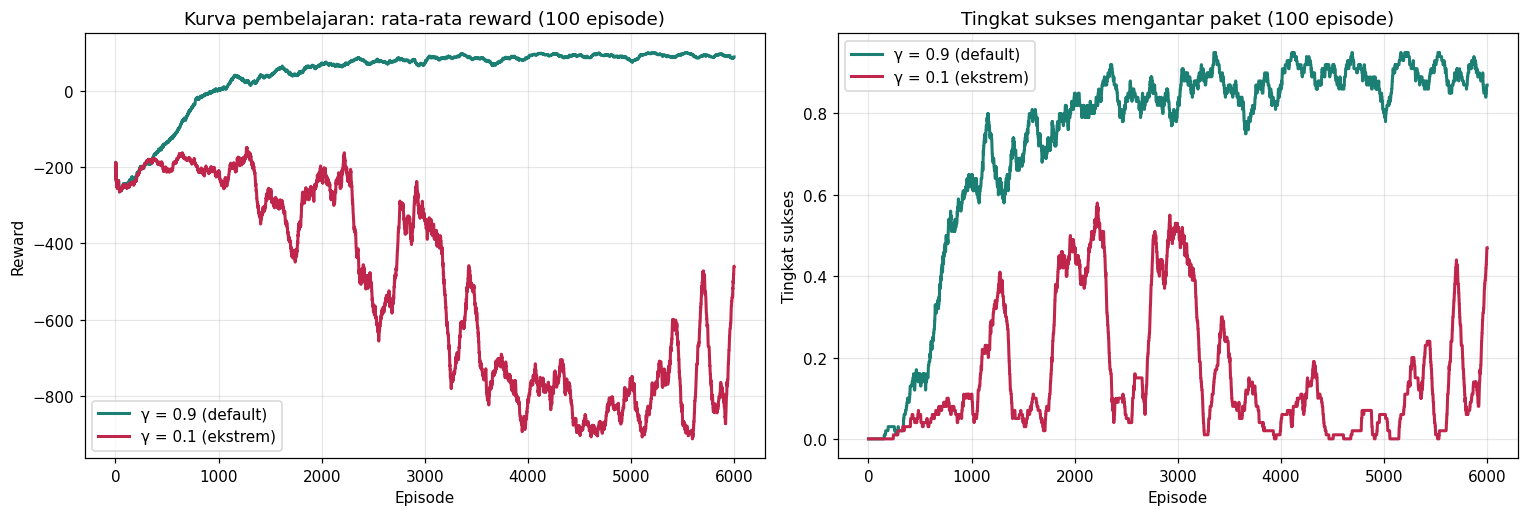

,Tingkat sukses,Baterai habis,Timeout,Rata-rata reward,Rata-rata langkah (sukses),Episode konvergensi,Reward latih (500 episode akhir)
γ = 0.9 (default),0.888,0.112,0.000,91.743,12.150901,2322,90.860
γ = 0.1 (ekstrem),0.504,0.000,0.496,-454.678,11.543651,tidak konvergen,-697.592


In [16]:
GAMMAS = {"γ = 0.9 (default)": 0.9, "γ = 0.1 (ekstrem)": 0.1}
exp = {}
for name, g in GAMMAS.items():
    params = {**HYPER, "gamma": g}
    q_g, h_g = train_q_learning(**params, seed=SEED)
    exp[name] = {"q": q_g, "hist": h_g, "eval": evaluate_policy(q_g, n_episodes=1000)}

colors = {"γ = 0.9 (default)": "#1b7f73", "γ = 0.1 (ekstrem)": "#c0264b"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, d in exp.items():
    axes[0].plot(moving_average(d["hist"]["rewards"], WINDOW), color=colors[name], linewidth=2, label=name)
    axes[1].plot(moving_average(d["hist"]["successes"], WINDOW), color=colors[name], linewidth=2, label=name)
axes[0].set_title("Kurva pembelajaran: rata-rata reward (100 episode)"); axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Reward")
axes[1].set_title("Tingkat sukses mengantar paket (100 episode)"); axes[1].set_xlabel("Episode"); axes[1].set_ylabel("Tingkat sukses")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
fig.savefig("figures/experiment_gamma.png", dpi=150, bbox_inches="tight")
plt.show()

summary = pd.DataFrame({name: d["eval"] for name, d in exp.items()}).T
summary["Episode konvergensi"] = [convergence_episode(d["hist"]["rewards"])[0] or "tidak konvergen" for d in exp.values()]
summary["Reward latih (500 episode akhir)"] = [d["hist"]["rewards"][-500:].mean() for d in exp.values()]
summary

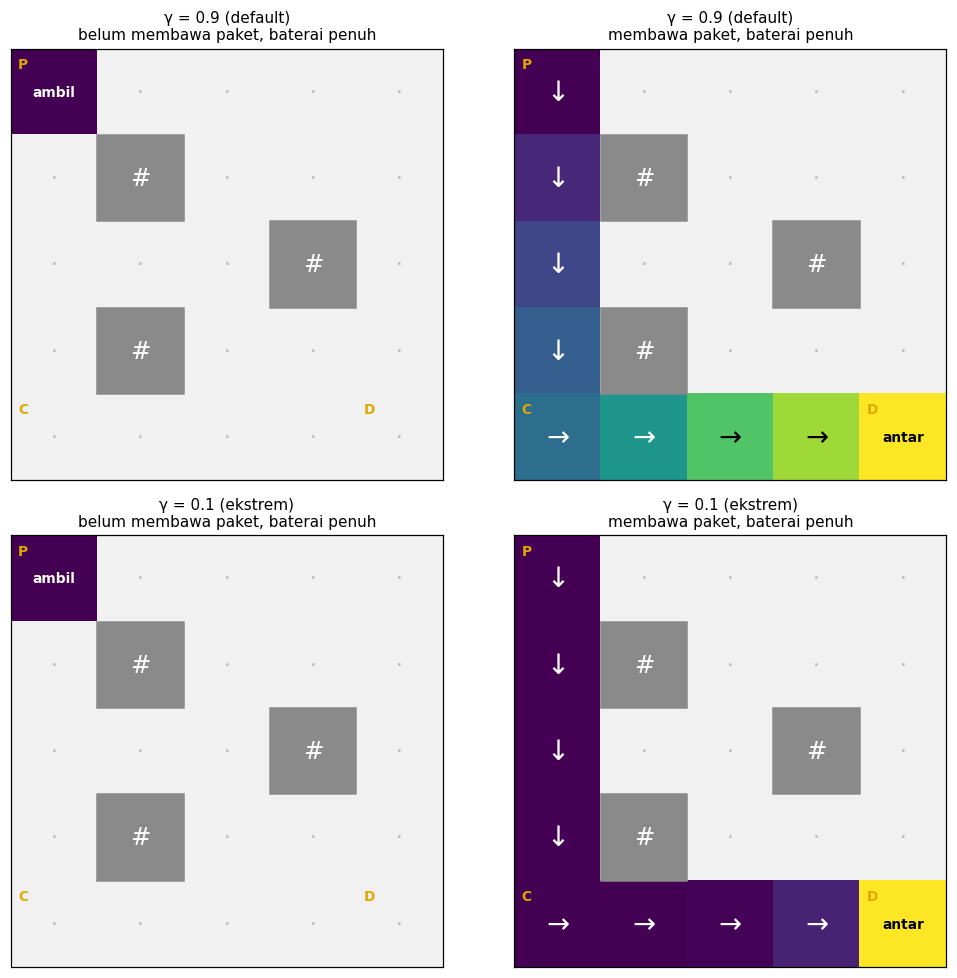

In [17]:
# Kebijakan yang dipelajari kedua model (hanya state yang dilalui kebijakan masing-masing)
fig, axes = plt.subplots(2, 2, figsize=(9.5, 9))
for i, (name, d) in enumerate(exp.items()):
    vis = greedy_visit_counts(d["q"])
    for j, pkg in enumerate([0, 1]):
        plot_policy(d["q"], pkg, 3, axes[i, j], visits=vis,
                    title=f"{name}\n{'belum membawa paket' if pkg == 0 else 'membawa paket'}, baterai penuh")
plt.tight_layout()
fig.savefig("figures/policy_gamma_compare.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Ketahanan hasil: ulangi dengan 5 seed berbeda untuk setiap γ
rows = []
for name, g in GAMMAS.items():
    for sd in [1, 2, 3, 4, 5]:
        q_s, _ = train_q_learning(**{**HYPER, "gamma": g}, seed=sd)
        e = evaluate_policy(q_s, n_episodes=500, seed=100 + sd)
        rows.append({"Model": name, "seed": sd, "Tingkat sukses": e["Tingkat sukses"], "Rata-rata reward": e["Rata-rata reward"]})
rob = pd.DataFrame(rows)
rob.groupby("Model")[["Tingkat sukses", "Rata-rata reward"]].agg(["mean", "std"]).round(3)

Tingkat sukses        Rata-rata reward         
                            mean    std             mean      std
Model                                                            
γ = 0.1 (ekstrem)          0.339  0.251         -613.830  281.695
γ = 0.9 (default)          0.894  0.008           92.658    1.043

### Analisis Eksperimen γ
*(Angka dari run dengan seed 42, kecuali disebut lain.)*

| | γ = 0.9 (default) | γ = 0.1 (ekstrem) |
|---|---|---|
| Tingkat sukses (1000 episode uji) | **88.8%** | 50.4% |
| Baterai habis | 11.2% | 0.0% |
| Timeout (100 langkah tanpa sampai) | 0.0% | **49.6%** |
| Rata-rata reward uji | **91.7** | −454.7 |
| Reward latih (500 episode terakhir) | 90.9 | −697.6 |
| Konvergensi | episode 2322 | tidak konvergen |
| Rata-rata 5 seed: tingkat sukses | 89.4% ± 0.8 | 33.9% ± 25.1 |
| Rata-rata 5 seed: reward | 92.7 ± 1.0 | −613.8 ± 281.7 |

**Pengamatan pada kurva:** dengan γ = 0.9, reward naik dan mendatar. Dengan γ = 0.1, kurva **tidak pernah naik** dan malah **memburuk** (sampai sekitar −900) ketika ϵ makin kecil. Tingkat suksesnya naik-turun tajam dan sering mendekati nol.

**Mengapa agen menjadi "miopik":** dengan γ = 0.1, reward masa depan dikalikan 0.1 pada setiap langkah, sehingga hadiah +100 di tujuan hampir tidak terasa dari beberapa langkah jauhnya. Agen hanya peduli konsekuensi langsung. Akibatnya muncul perilaku yang unik: pada state dengan **baterai rendah di tengah peta**, bergerak berisiko 30% terkena −50, sedangkan manfaat sampai ke tujuan tidak terlihat. Q-Table yang dihasilkan menunjukkan hampir semua aksi bernilai sekitar **−12**, dan aksi "terbaik" justru **aksi tidak valid** (misalnya menabrak rintangan) yang tidak memindahkan robot. Agen pun **membeku** di tempat dan mengulang aksi tidak valid (−11 per langkah) sampai timeout, sehingga satu episode bisa bernilai hampir −1000. Itu menjelaskan nol kasus baterai habis tetapi hampir separuh episode timeout. Selama ϵ masih cukup besar, aksi acak sesekali memecah kebuntuan itu dan membuat tingkat sukses sempat naik (sekitar 50% pada episode 2000-3000). Ketika ϵ makin kecil, agen makin bergantung pada kebijakan miopiknya sendiri sehingga makin sering membeku, dan reward pelatihan justru makin buruk.

**Perbandingan kebijakan:** γ = 0.9 menghasilkan jalur lengkap ambil, turun, isi baterai, lalu ke tujuan. Dengan γ = 0.1 agen masih belajar mengambil paket (bonus +19 bersifat langsung), tetapi tidak membangun jalur panjang dengan andal ke tujuan.

**Ketahanan:** pada 5 seed berbeda, γ = 0.9 konsisten (89.4% ± 0.8), sedangkan γ = 0.1 sangat tidak stabil (33.9% ± 25.1), artinya hasilnya bergantung pada keberuntungan awal pelatihan.

**Kesimpulan eksperimen:** untuk tugas dengan banyak langkah antara aksi dan hadiah, γ harus cukup besar agar agen "melihat" hadiah jangka panjang. Di sini γ = 0.9 sangat sesuai, sedangkan γ = 0.1 membuat agen gagal belajar.

## 6. Kesimpulan

1. **Q-Learning berhasil** mempelajari kebijakan yang efektif untuk Robot Kurir. Pada 1000 episode uji tanpa eksplorasi, tingkat sukses **88.8%**, rata-rata reward **91.7**, dan rata-rata **12.15 langkah** per pengantaran sukses (minimum teoretis 10-11).
2. **Konvergensi** tercapai sekitar episode **2322** dari 6000 episode. Fluktuasi yang tersisa berasal dari sifat stokastik penurunan baterai, bukan dari agen yang belum belajar.
3. **Kebijakan logis dan dapat dijelaskan:** ambil paket, lewati charger di jalur, isi baterai bila tidak penuh, lalu serahkan di tujuan, bahkan kembali ke charger saat baterai sedang terlalu dekat dengan batas bahaya.
4. **Hiperparameter berpengaruh besar.** α = 0.1 lebih stabil daripada α = 0.8 pada lingkungan stokastik (88.8% vs 73.4% sukses). γ yang terlalu rendah (0.1) membuat agen miopik, membeku, dan gagal belajar (50.4% timeout, reward uji −454.7), sedangkan γ = 0.9 konsisten pada 5 seed (89.4% ± 0.8).
5. **Keterbatasan:** Q-Learning berbasis tabel hanya cocok untuk ruang state kecil (200 state di sini, dan hanya 128 yang pernah dikunjungi). Untuk state yang jauh lebih besar atau kontinu, diperlukan pendekatan seperti Deep Q-Network (DQN).

## 7. Menyimpan Hasil

In [19]:
np.save("q_table.npy", q_table)
pd.DataFrame(q_table, columns=ACTIONS,
             index=[str(decode(s)) for s in range(N_STATES)]).to_csv("q_table.csv")
print("Tersimpan: q_table.npy, q_table.csv, dan gambar di folder figures/")

Tersimpan: q_table.npy, q_table.csv, dan gambar di folder figures/
